# 01 — Repeat Journal: Ghatora et al. (2024)

- **Judul Jurnal:** *Sentiment Analysis of Product Reviews Using Machine Learning and Pre-Trained LLM*
- **Jurnal:** *Big Data and Cognitive Computing* (MDPI), Vol. 8, Issue 12, Art. 199 (2024)
- **DOI:** https://doi.org/10.3390/bdcc8120199
- **Dataset Asli:** Flipkart Product Reviews with Sentiment Dataset (`Dataset-SA.csv`, 205.052 baris)
- **NIM:** `09040624091` — Muhammad Iqbal Rizanta

Notebook ini dibuat sederhana (gaya tutorial Colab) dan mengikuti persis langkah Section 3.1–4.2 pada jurnal.

In [1]:
# 1. Import Library Utama
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

sns.set_theme(style='whitegrid')
ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists() and (ROOT.parent.parent / 'data').exists():
    ROOT = ROOT.parent.parent
DATA_PATH = ROOT / 'data' / 'raw' / 'journal_repeat' / 'Dataset-SA.csv'
print('Dataset Path:', DATA_PATH)

Dataset Path: C:\big-data-analytic\data\raw\journal_repeat\Dataset-SA.csv


In [2]:
# 2. Load Dataset Asli & Cek Distribusi Awal (Tabel 1 Jurnal)
df = pd.read_csv(DATA_PATH)
print('Ukuran Dataset Asli:', df.shape)
display(df.head(5))
print('\nJumlah Missing Value per Kolom:')
print(df.isnull().sum())
print('\nDistribusi Sentimen Awal (Tabel 1):')
print(df['Sentiment'].value_counts())

Ukuran Dataset Asli: (205052, 6)


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral



Jumlah Missing Value per Kolom:
product_name         0
product_price        0
Rate                 0
Review           24664
Summary             11
Sentiment            0
dtype: int64

Distribusi Sentimen Awal (Tabel 1):


Sentiment
positive    166581
negative     28232
neutral      10239
Name: count, dtype: int64


Ukuran Setelah Hapus Null: (180379, 6)
Sentiment
positive    147171
negative     24401
neutral       8807
Name: count, dtype: int64


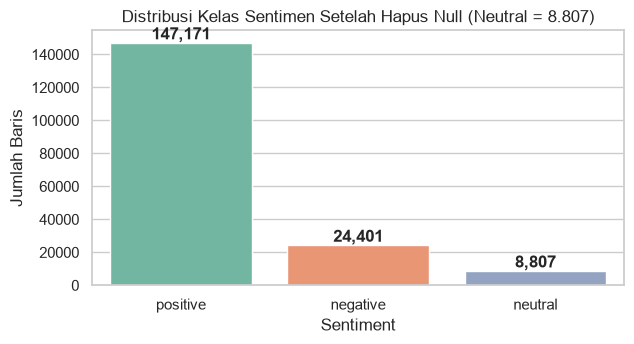

In [3]:
# 3. Hapus Baris Null sesuai Section 3.1.4 Jurnal
df_clean = df.dropna(subset=['Review', 'Summary', 'Sentiment']).reset_index(drop=True)
print('Ukuran Setelah Hapus Null:', df_clean.shape)
counts = df_clean['Sentiment'].value_counts()
print(counts)

plt.figure(figsize=(6.5, 3.6))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette='Set2', legend=False)
plt.title('Distribusi Kelas Sentimen Setelah Hapus Null (Neutral = 8.807)')
plt.ylabel('Jumlah Baris')
for i, v in enumerate(counts.values):
    plt.text(i, v + 2000, f'{v:,}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [4]:
# 4. Fungsi Cleaning Teks (Section 3.2a) & Fungsi Eksperimen (Section 3.2b-3.2c)
stemmer = PorterStemmer()
stop_words = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = re.sub(r'http\S+|www\S+|#\w+|<.*?>', ' ', str(text).lower())
    text = re.sub(r'[^a-z\s]', ' ', text)
    return ' '.join(stemmer.stem(w) for w in text.split() if w not in stop_words and len(w) > 1)

def repeat_experiment(df_in, col_name, n_per_class):
    # Class balancing sesuai jurnal
    df_bal = pd.concat([g.sample(n=n_per_class, random_state=42) for _, g in df_in.groupby('Sentiment')], ignore_index=True)
    # Bag of Words (CountVectorizer)
    X = CountVectorizer(max_features=1500).fit_transform(df_bal[col_name].apply(clean_text)).toarray()
    y = df_bal['Sentiment'].to_numpy(dtype=str)
    # Train/Test Split 80:20
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

    models = {
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
        'Naive Bayes': GaussianNB(),
        'SVM': LinearSVC(random_state=42, dual='auto', max_iter=2000),
    }
    rows, cms = [], {}
    labels = ['negative', 'neutral', 'positive']
    for name, clf in models.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        rows.append({
            'Experiment': col_name,
            'Model': name,
            'Repeat_Accuracy': round(accuracy_score(y_test, y_pred), 3),
            'Repeat_Precision': round(precision_score(y_test, y_pred, average='macro', zero_division=0), 3),
            'Repeat_Recall': round(recall_score(y_test, y_pred, average='macro', zero_division=0), 3),
            'Repeat_F1': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 3),
        })
        cms[name] = confusion_matrix(y_test, y_pred, labels=labels)
    return pd.DataFrame(rows), cms

In [5]:
# 5. Jalankan Eksperimen 1 (Review: 8.807 x 3) & Eksperimen 2 (Summary: 3.000 x 3)
res_review, cms_review = repeat_experiment(df_clean, 'Review', 8807)
res_summary, cms_summary = repeat_experiment(df_clean, 'Summary', 3000)
df_repeat = pd.concat([res_review, res_summary], ignore_index=True)

# Bandingkan langsung dengan angka Tabel 2 & Tabel 3 Jurnal Ghatora et al. (2024)
df_paper = pd.DataFrame([
    {'Experiment': 'Review',  'Model': 'Random Forest', 'Paper_Accuracy': 0.680, 'Paper_F1': 0.672},
    {'Experiment': 'Review',  'Model': 'Naive Bayes',   'Paper_Accuracy': 0.449, 'Paper_F1': 0.347},
    {'Experiment': 'Review',  'Model': 'SVM',           'Paper_Accuracy': 0.682, 'Paper_F1': 0.673},
    {'Experiment': 'Summary', 'Model': 'Random Forest', 'Paper_Accuracy': 0.767, 'Paper_F1': 0.766},
    {'Experiment': 'Summary', 'Model': 'Naive Bayes',   'Paper_Accuracy': 0.426, 'Paper_F1': 0.380},
    {'Experiment': 'Summary', 'Model': 'SVM',           'Paper_Accuracy': 0.768, 'Paper_F1': 0.768},
])
df_compare = df_paper.merge(df_repeat, on=['Experiment', 'Model'])
df_compare['Selisih_Acc'] = (df_compare['Repeat_Accuracy'] - df_compare['Paper_Accuracy']).round(3)
display(df_compare)

,Experiment,Model,Paper_Accuracy,Paper_F1,Repeat_Accuracy,Repeat_Precision,Repeat_Recall,Repeat_F1,Selisih_Acc
0,Review,Random Forest,0.680,0.672,0.690,0.685,0.690,0.681,0.010
1,Review,Naive Bayes,0.449,0.347,0.457,0.525,0.457,0.356,0.008
2,Review,SVM,0.682,0.673,0.690,0.685,0.690,0.681,0.008
3,Summary,Random Forest,0.767,0.766,0.766,0.765,0.766,0.764,-0.001
4,Summary,Naive Bayes,0.426,0.380,0.452,0.539,0.452,0.416,0.026
5,Summary,SVM,0.768,0.768,0.754,0.755,0.754,0.753,-0.014


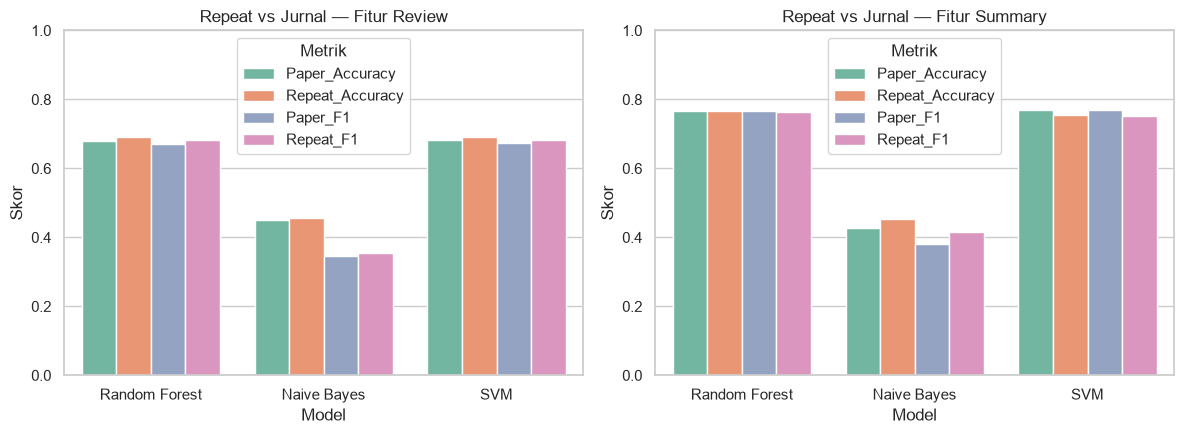

In [6]:
# 6. Visualisasi Perbandingan Hasil Repeat vs Hasil Jurnal
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, exp in zip(axes, ['Review', 'Summary']):
    sub = df_compare[df_compare['Experiment'] == exp]
    melted = sub.melt(id_vars='Model', value_vars=['Paper_Accuracy', 'Repeat_Accuracy', 'Paper_F1', 'Repeat_F1'], var_name='Metrik', value_name='Skor')
    sns.barplot(data=melted, x='Model', y='Skor', hue='Metrik', palette='Set2', ax=ax)
    ax.set_title(f'Repeat vs Jurnal — Fitur {exp}')
    ax.set_ylim(0, 1.0)
plt.tight_layout()
plt.show()